# Problem Statement: E-Commerce Shopper Behaviour Analysis

- Analyse customer demographics and shopping preferences.
- Identify patterns in purchasing behaviour.
- Understand factors influencing customer purchase decisions.
- Explore relationships between customer attributes and shopping habits.
- Identify trends through Exploratory Data Analysis (EDA).
- Derive meaningful insights to support better e-commerce business decisions.

In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os

warnings.filterwarnings('ignore')

In [7]:
df = pd.read_excel('e_commerce_shopper_behaviour_and_lifestyle.xlsx')

df.to_csv('e_commerce_shopper_behaviour_and_lifestyle.csv', index=False)

In [8]:
df = pd.read_csv('e_commerce_shopper_behaviour_and_lifestyle.csv')

In [9]:
df.head()

,user_id,age,gender,country,urban_rural,income_level,employment_status,education_level,relationship_status,has_children,...,cart_items_average,checkout_abandonments_per_month,purchase_conversion_rate,app_usage_frequency,notification_response_rate,account_age_months,last_purchase_date,social_sharing_frequency,premium_subscription,return_rate
0,1,56,Female,Germany,Suburban,90860,Self-employed,Associate Degree,Single,0,...,10,2,62,7,74,19,2025-06-22,6,1,50
1,2,69,Male,Japan,Suburban,35423,Unemployed,Bachelor,Single,1,...,5,7,54,5,23,8,2026-07-25,3,0,37
2,3,46,Female,India,Urban,21467,Self-employed,Associate Degree,Married,1,...,3,3,33,7,12,13,2026-02-26,6,0,53
3,4,32,Male,Canada,Urban,41770,Self-employed,Bachelor,Widowed,0,...,5,9,26,4,19,9,2026-10-27,7,0,98
4,5,60,Female,Japan,Urban,183882,Employed,Associate Degree,Widowed,1,...,8,0,18,7,30,3,2026-06-23,3,0,86


In [10]:
df.tail()

,user_id,age,gender,country,urban_rural,income_level,employment_status,education_level,relationship_status,has_children,...,cart_items_average,checkout_abandonments_per_month,purchase_conversion_rate,app_usage_frequency,notification_response_rate,account_age_months,last_purchase_date,social_sharing_frequency,premium_subscription,return_rate
999995,999996,36,Female,France,Urban,192880,Student,Master,In a relationship,0,...,4,3,26,2,50,21,2025-06-27,2,1,93
999996,999997,37,Male,Canada,Urban,197111,Unemployed,Master,Divorced,0,...,10,9,31,5,78,15,2025-06-05,7,1,97
999997,999998,71,Male,UK,Urban,171275,Unemployed,Bachelor,Married,1,...,6,5,19,7,8,16,2026-09-25,5,0,96
999998,999999,30,Female,Germany,Urban,124983,Employed,High School,Single,0,...,4,2,56,5,8,11,2026-10-25,2,0,46
999999,1000000,61,Male,China,Rural,65396,Student,Bachelor,In a relationship,1,...,10,10,79,0,64,1,2025-12-17,5,0,43


In [11]:
df.shape

(1000000, 60)

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 60 columns):
 #   Column                           Non-Null Count    Dtype
---  ------                           --------------    -----
 0   user_id                          1000000 non-null  int64
 1   age                              1000000 non-null  int64
 2   gender                           1000000 non-null  str  
 3   country                          1000000 non-null  str  
 4   urban_rural                      1000000 non-null  str  
 5   income_level                     1000000 non-null  int64
 6   employment_status                1000000 non-null  str  
 7   education_level                  1000000 non-null  str  
 8   relationship_status              1000000 non-null  str  
 9   has_children                     1000000 non-null  int64
 10  household_size                   1000000 non-null  int64
 11  occupation                       1000000 non-null  str  
 12  ethnicity                 

In [13]:
df.describe()

,user_id,age,income_level,has_children,household_size,weekly_purchases,monthly_spend,cart_abandonment_rate,review_writing_frequency,average_order_value,...,wishlist_items_count,cart_items_average,checkout_abandonments_per_month,purchase_conversion_rate,app_usage_frequency,notification_response_rate,account_age_months,social_sharing_frequency,premium_subscription,return_rate
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,...,1000000.00000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,500000.500000,49.003377,104994.565463,0.399426,5.505323,9.993011,2498.775654,40.212257,3.450584,255.031632,...,9.99766,5.494336,4.997523,50.001442,3.498840,49.989012,12.509560,3.593763,0.359415,50.004949
std,288675.278932,18.193959,54851.476652,0.489781,2.873725,6.055124,1444.208674,25.433343,1.856725,141.708466,...,6.05453,2.870467,3.162831,29.163437,2.291567,29.151948,6.922197,1.932566,0.479829,29.159616
min,1.000000,18.000000,10000.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,10.000000,...,0.00000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,250000.750000,33.000000,57466.000000,0.000000,3.000000,5.000000,1249.000000,18.000000,2.000000,132.000000,...,5.00000,3.000000,2.000000,25.000000,1.000000,25.000000,7.000000,2.000000,0.000000,25.000000
50%,500000.500000,49.000000,105013.000000,0.000000,6.000000,10.000000,2498.000000,40.000000,3.000000,255.000000,...,10.00000,5.000000,5.000000,50.000000,3.000000,50.000000,13.000000,4.000000,0.000000,50.000000
75%,750000.250000,65.000000,152497.000000,1.000000,8.000000,15.000000,3750.000000,62.000000,5.000000,378.000000,...,15.00000,8.000000,8.000000,75.000000,6.000000,75.000000,19.000000,5.000000,1.000000,75.000000
max,1000000.000000,80.000000,200000.000000,1.000000,10.000000,20.000000,5000.000000,90.000000,8.000000,500.000000,...,20.00000,10.000000,10.000000,100.000000,7.000000,100.000000,24.000000,8.000000,1.000000,100.000000


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.dtypes

user_id                            int64
age                                int64
gender                               str
country                              str
urban_rural                          str
income_level                       int64
employment_status                    str
education_level                      str
relationship_status                  str
has_children                       int64
household_size                     int64
occupation                           str
ethnicity                            str
language_preference                  str
device_type                          str
weekly_purchases                   int64
monthly_spend                      int64
cart_abandonment_rate              int64
review_writing_frequency           int64
average_order_value                int64
preferred_payment_method             str
coupon_usage_frequency             int64
loyalty_program_member             int64
referral_count                     int64
product_category

# 1. Univariate Analysis

Univariate analysis focuses on examining individual variables to understand their distributions, central tendencies, spread, and anomalies.

### Objectives:
- Analyse income level and monthly spending distributions.
- Examine daily session time and product views.
- Investigate cart abandonment and return rates.
- Explore demographic distributions across device type, country, education level, and employment status.

### 1.1 Income Level & Spending Distribution

- Examine the distribution of income levels and monthly spending across users.
- Identify spending patterns and variations.
- Determine whether monthly spending is heavily right-skewed.
- Identify potential high-spending outliers.

In [16]:
df[['income_level', 'monthly_spend']].describe()

,income_level,monthly_spend
count,1000000.000000,1000000.000000
mean,104994.565463,2498.775654
std,54851.476652,1444.208674
min,10000.000000,0.000000
25%,57466.000000,1249.000000
50%,105013.000000,2498.000000
75%,152497.000000,3750.000000
max,200000.000000,5000.000000


In [17]:
df[['income_level', 'monthly_spend']].skew()

income_level    -0.000053
monthly_spend    0.001212
dtype: float64

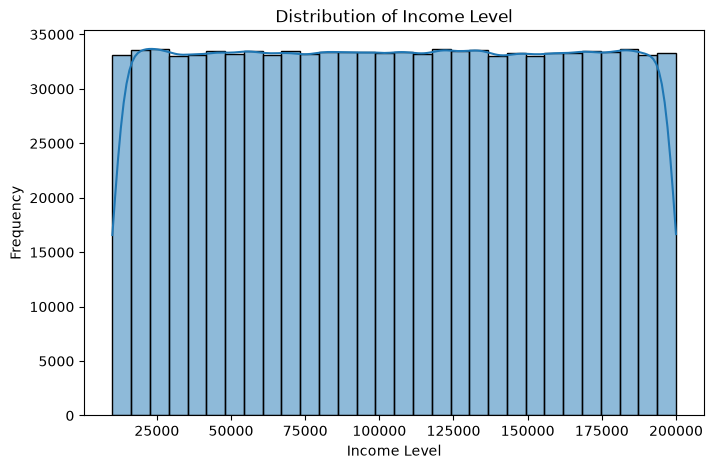

In [18]:
plt.figure(figsize=(8, 5))
sns.histplot(df['income_level'], kde=True, bins=30)
plt.title('Distribution of Income Level')
plt.xlabel('Income Level')
plt.ylabel('Frequency')
plt.show()

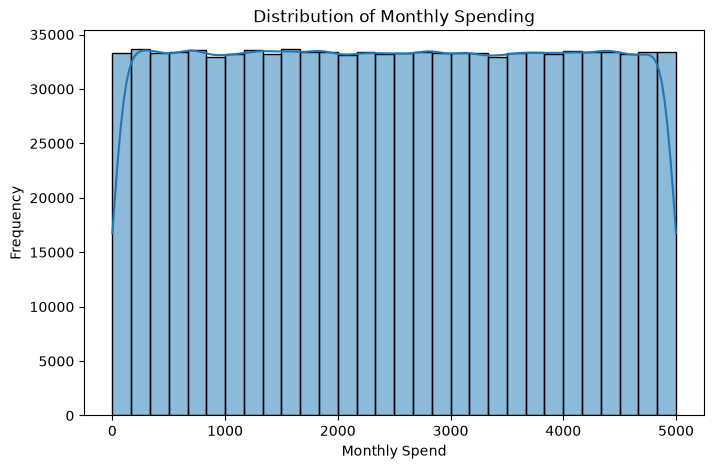

In [19]:
plt.figure(figsize=(8, 5))
sns.histplot(df['monthly_spend'], kde=True, bins=30)
plt.title('Distribution of Monthly Spending')
plt.xlabel('Monthly Spend')
plt.ylabel('Frequency')
plt.show()

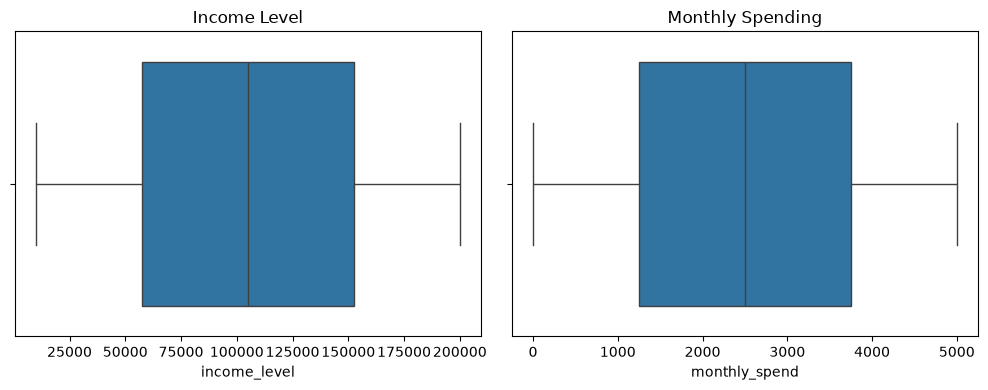

In [20]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=df['income_level'])
plt.title('Income Level')

plt.subplot(1, 2, 2)
sns.boxplot(x=df['monthly_spend'])
plt.title('Monthly Spending')

plt.tight_layout()
plt.show()

In [21]:
df['monthly_spend'].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

0.25    1249.0
0.50    2498.0
0.75    3750.0
0.90    4499.0
0.95    4751.0
0.99    4951.0
Name: monthly_spend, dtype: float64

### Conclusion

- Both income level and monthly spending show nearly symmetrical distributions.
- Monthly spending has negligible positive skewness (0.0012).
- The mean (2498.78) and median (2498) are almost identical.
- No significant right-skewness towards high-spending customers is observed.

### 1.2 Engagement Baselines

- Examine the distribution of daily session time and product views per day.
- Identify common user engagement patterns.
- Determine whether users prefer quick browsing sessions or extended platform engagement.
- Understand the overall level of platform interaction.

In [22]:
df[['daily_session_time_minutes', 'product_views_per_day']].describe()

,daily_session_time_minutes,product_views_per_day
count,1000000.000000,1000000.000000
mean,60.014414,25.018014
std,34.939233,14.721810
min,0.000000,0.000000
25%,30.000000,12.000000
50%,60.000000,25.000000
75%,90.000000,38.000000
max,120.000000,50.000000


In [23]:
df[['daily_session_time_minutes', 'product_views_per_day']].skew()

daily_session_time_minutes   -0.001709
product_views_per_day        -0.001492
dtype: float64

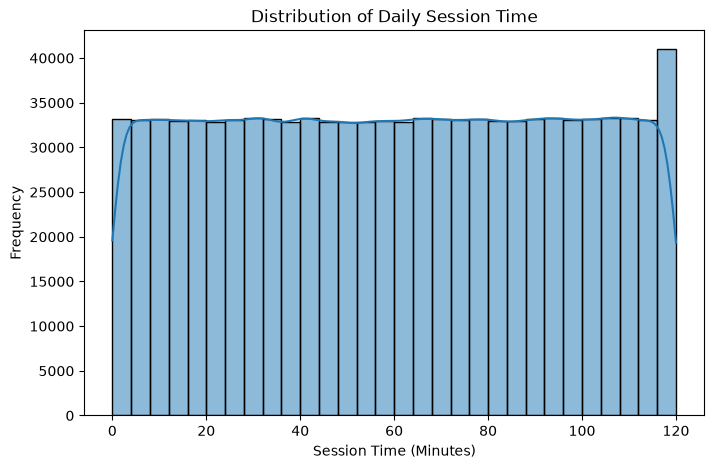

In [24]:
plt.figure(figsize=(8, 5))
sns.histplot(df['daily_session_time_minutes'], bins=30, kde=True)
plt.title('Distribution of Daily Session Time')
plt.xlabel('Session Time (Minutes)')
plt.ylabel('Frequency')
plt.show()


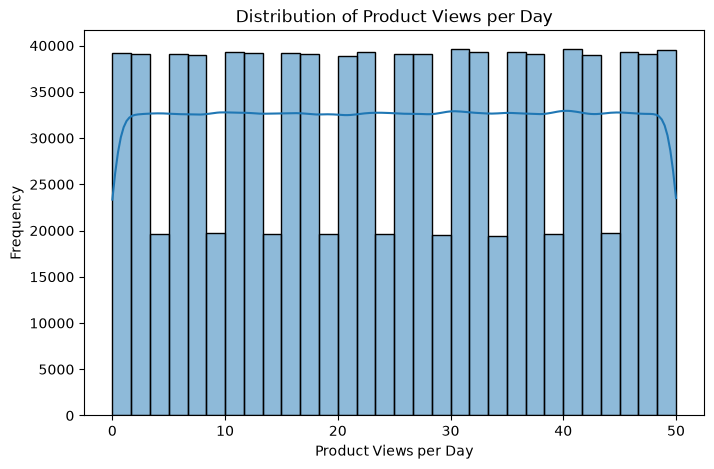

In [25]:
plt.figure(figsize=(8, 5))
sns.histplot(df['product_views_per_day'], bins=30, kde=True)
plt.title('Distribution of Product Views per Day')
plt.xlabel('Product Views per Day')
plt.ylabel('Frequency')
plt.show()

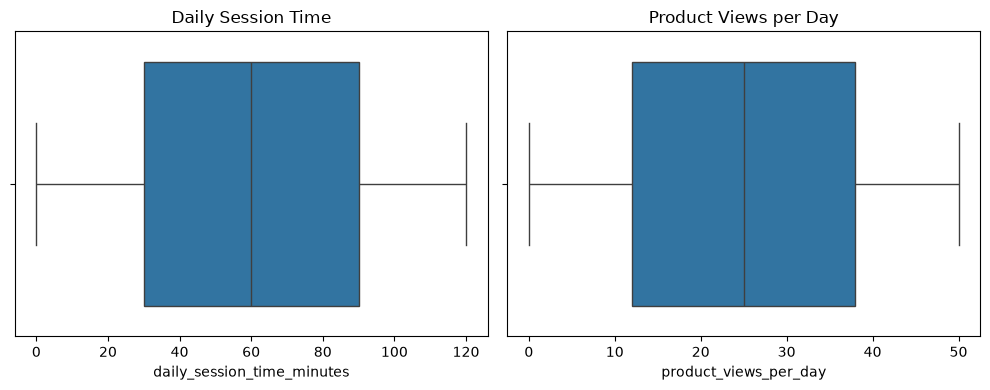

In [26]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=df['daily_session_time_minutes'])
plt.title('Daily Session Time')

plt.subplot(1, 2, 2)
sns.boxplot(x=df['product_views_per_day'])
plt.title('Product Views per Day')

plt.tight_layout()
plt.show()

In [27]:
df[['daily_session_time_minutes', 'product_views_per_day']].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

,daily_session_time_minutes,product_views_per_day
0.25,30.0,12.0
0.50,60.0,25.0
0.75,90.0,38.0
0.90,108.0,45.0
0.95,114.0,48.0
0.99,119.0,50.0


### Conclusion

- Average daily session time is approximately 60 minutes, with a median of 60 minutes.
- Users view an average of 25 products per day.
- Both variables show negligible negative skewness.
- Session time ranges from 0 to 120 minutes, while product views range from 0 to 50.
- The distributions indicate balanced engagement patterns across users.

### 1.3 Friction Metrics

- Examine the distribution of cart abandonment rates and return rates.
- Understand the typical level of shopping friction among users.
- Identify users with extremely high cart abandonment rates (above 80%).
- Measure the proportion of users experiencing extreme cart abandonment.

In [28]:
df[['cart_abandonment_rate', 'return_rate']].describe()

,cart_abandonment_rate,return_rate
count,1000000.000000,1000000.000000
mean,40.212257,50.004949
std,25.433343,29.159616
min,0.000000,0.000000
25%,18.000000,25.000000
50%,40.000000,50.000000
75%,62.000000,75.000000
max,90.000000,100.000000


In [29]:
df[['cart_abandonment_rate', 'return_rate']].skew()

cart_abandonment_rate    0.048655
return_rate             -0.000360
dtype: float64

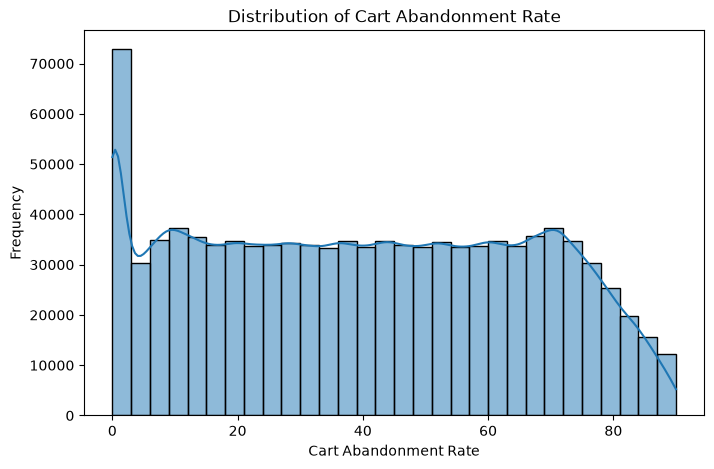

In [30]:
plt.figure(figsize=(8, 5))
sns.histplot(df['cart_abandonment_rate'], bins=30, kde=True)
plt.title('Distribution of Cart Abandonment Rate')
plt.xlabel('Cart Abandonment Rate')
plt.ylabel('Frequency')
plt.show()

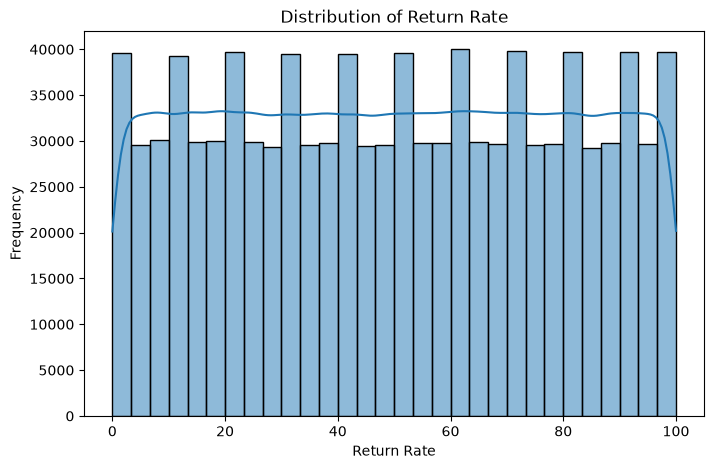

In [31]:
plt.figure(figsize=(8, 5))
sns.histplot(df['return_rate'], bins=30, kde=True)
plt.title('Distribution of Return Rate')
plt.xlabel('Return Rate')
plt.ylabel('Frequency')
plt.show()

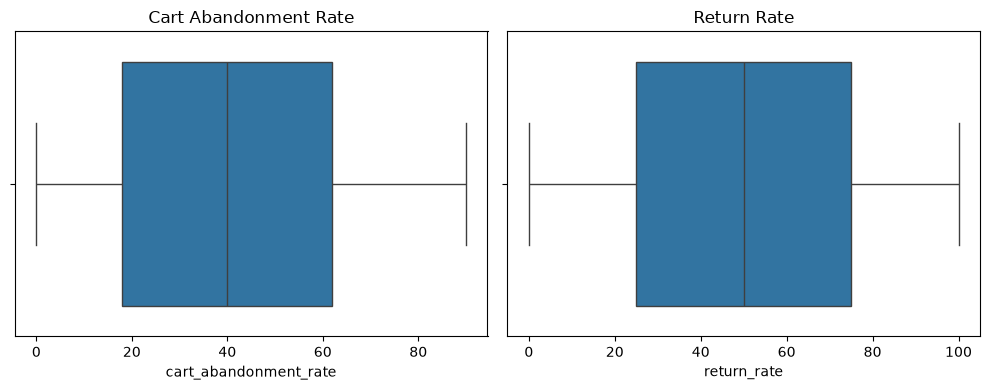

In [32]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=df['cart_abandonment_rate'])
plt.title('Cart Abandonment Rate')

plt.subplot(1, 2, 2)
sns.boxplot(x=df['return_rate'])
plt.title('Return Rate')

plt.tight_layout()
plt.show()

In [33]:
extreme_users = (df['cart_abandonment_rate'] > 80).sum()
total_users = len(df)

print("Users with cart abandonment above 80%:", extreme_users)
print("Total users:", total_users)
print("Percentage:", round((extreme_users / total_users) * 100, 2), "%")

Users with cart abandonment above 80%: 47708
Total users: 1000000
Percentage: 4.77 %


In [34]:
print("MEAN:")
print(df[['cart_abandonment_rate', 'return_rate']].mean())

print("\nMEDIAN:")
print(df[['cart_abandonment_rate', 'return_rate']].median())

MEAN:
cart_abandonment_rate    40.212257
return_rate              50.004949
dtype: float64

MEDIAN:
cart_abandonment_rate    40.0
return_rate              50.0
dtype: float64


### Conclusion

- Average cart abandonment rate is **40.21%**, while the average return rate is **50.00%**.
- Both distributions are approximately symmetrical, with negligible skewness.
- **4.77% of users (47,708)** have cart abandonment rates above 80%.
- Overall, most users show moderate shopping friction, while a small proportion experience extremely high cart abandonment.

### 1.4 Demographic Analysis

- Examine the distribution of users across categorical demographic variables.
- Identify the dominant device types, countries, education levels, and employment statuses.
- Understand the most common demographic segments within the dataset.

In [35]:
df['device_type'].value_counts()

device_type
Mobile     600247
Desktop    299845
Tablet      99908
Name: count, dtype: int64

In [36]:
df['country'].value_counts()

country
Brazil       100476
Canada       100357
China        100190
Germany      100097
USA           99996
France        99992
Australia     99974
India         99899
UK            99875
Japan         99144
Name: count, dtype: int64

In [37]:
df['education_level'].value_counts()

education_level
Bachelor            299953
High School         299391
Associate Degree    200989
Master              149699
PhD                  49968
Name: count, dtype: int64

In [38]:
df['employment_status'].value_counts()

employment_status
Retired          200246
Unemployed       200225
Employed         199988
Student          199949
Self-employed    199592
Name: count, dtype: int64

In [39]:
for col in ['device_type', 'country', 'education_level', 'employment_status']:
    print(f"\n{col.upper()}")
    print((df[col].value_counts(normalize=True) * 100).round(2))


DEVICE_TYPE
device_type
Mobile     60.02
Desktop    29.98
Tablet      9.99
Name: proportion, dtype: float64

COUNTRY
country
Brazil       10.05
Canada       10.04
China        10.02
Germany      10.01
USA          10.00
France       10.00
Australia    10.00
India         9.99
UK            9.99
Japan         9.91
Name: proportion, dtype: float64

EDUCATION_LEVEL
education_level
Bachelor            30.00
High School         29.94
Associate Degree    20.10
Master              14.97
PhD                  5.00
Name: proportion, dtype: float64

EMPLOYMENT_STATUS
employment_status
Retired          20.02
Unemployed       20.02
Employed         20.00
Student          19.99
Self-employed    19.96
Name: proportion, dtype: float64


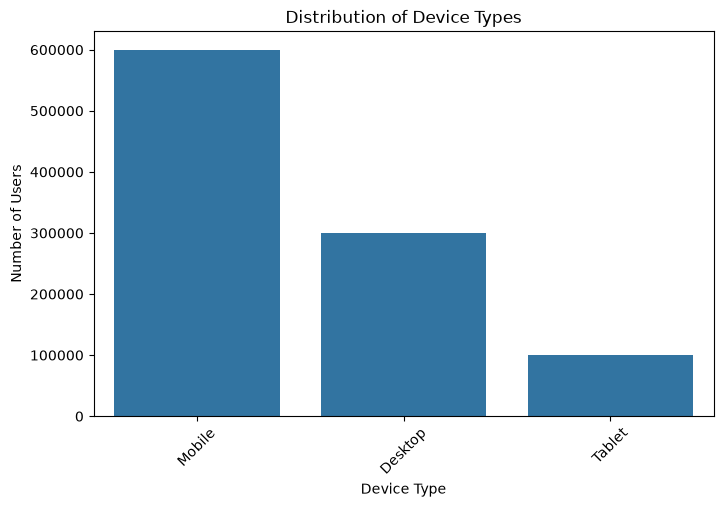

In [40]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='device_type', order=df['device_type'].value_counts().index)
plt.title('Distribution of Device Types')
plt.xlabel('Device Type')
plt.ylabel('Number of Users')
plt.xticks(rotation=45)
plt.show()

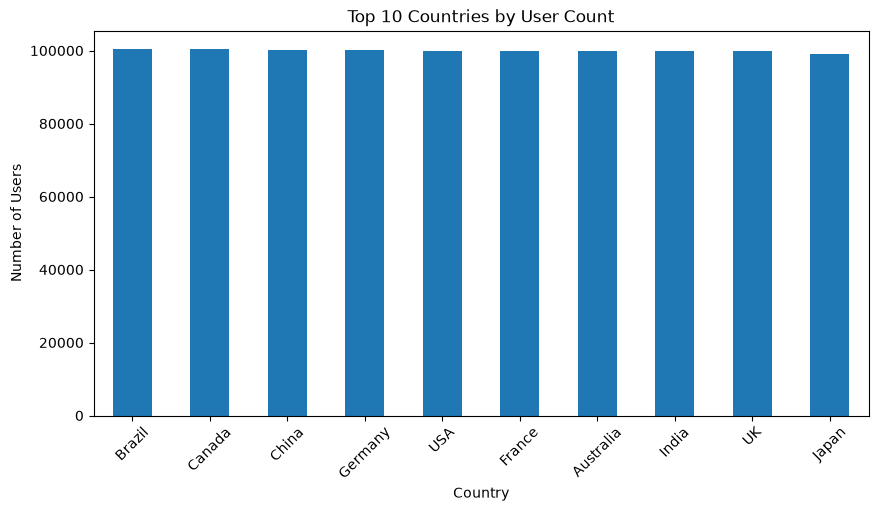

In [41]:
plt.figure(figsize=(10, 5))
df['country'].value_counts().head(10).plot(kind='bar')
plt.title('Top 10 Countries by User Count')
plt.xlabel('Country')
plt.ylabel('Number of Users')
plt.xticks(rotation=45)
plt.show()

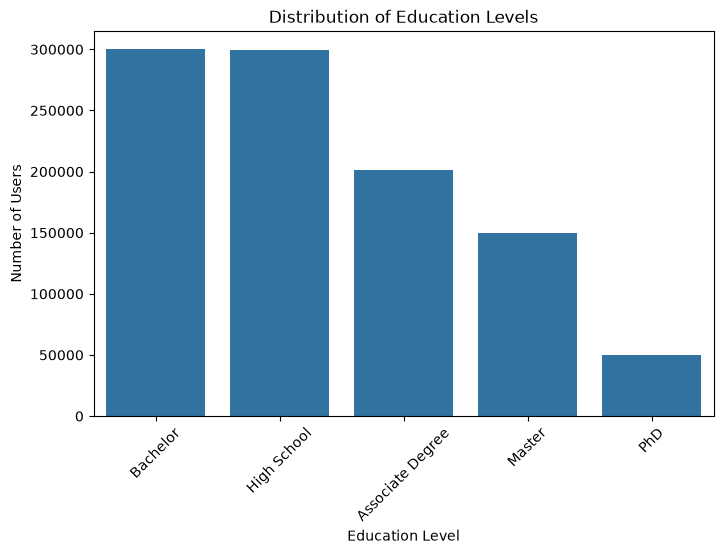

In [42]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='education_level', order=df['education_level'].value_counts().index)
plt.title('Distribution of Education Levels')
plt.xlabel('Education Level')
plt.ylabel('Number of Users')
plt.xticks(rotation=45)
plt.show()

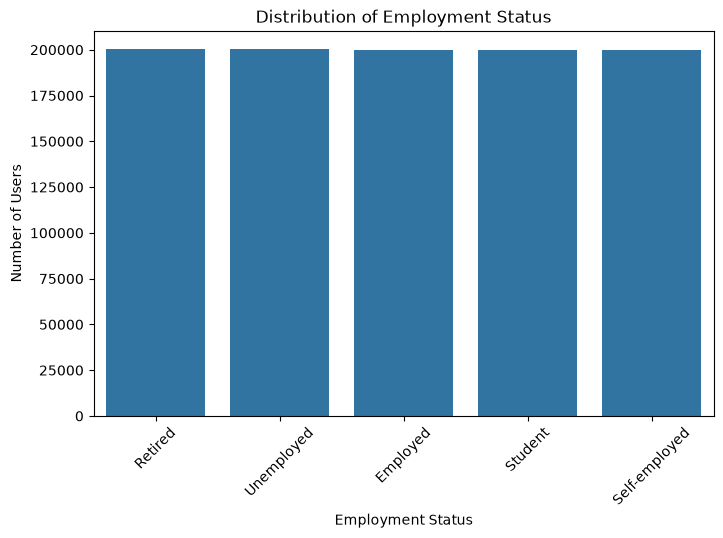

In [43]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='employment_status', order=df['employment_status'].value_counts().index)
plt.title('Distribution of Employment Status')
plt.xlabel('Employment Status')
plt.ylabel('Number of Users')
plt.xticks(rotation=45)
plt.show()

In [44]:
columns = ['device_type', 'country', 'education_level', 'employment_status']

for col in columns:
    dominant = df[col].value_counts().idxmax()
    count = df[col].value_counts().max()
    percentage = (count / len(df)) * 100

    print(f"{col}: {dominant} ({count} users, {percentage:.2f}%)")

device_type: Mobile (600247 users, 60.02%)
country: Brazil (100476 users, 10.05%)
education_level: Bachelor (299953 users, 30.00%)
employment_status: Retired (200246 users, 20.02%)


### Conclusion

- **Mobile** is the dominant device type, accounting for 60.02% of users.
- **Brazil** has the highest country representation at 10.05%.
- **Bachelor's degree** holders form the largest education group at 30.00%.
- Employment status is almost evenly distributed, with each category representing approximately 20% of users.
- Overall, the dataset shows diverse demographics with a clear preference for mobile devices.

In [3]:
# Scatter plot for two numerical variables

def scatter_graph(x, y, title, palette="viridis"):

    data = df[[x, y]].dropna()

    # Sample for visualization; correlation uses all records
    sample = data.sample(
        min(12000, len(data)),
        random_state=42
    )

    correlation = data[x].corr(data[y])

    fig, ax = plt.subplots(figsize=(10, 6))

    # Colourful scatter points
    points = ax.scatter(
        sample[x],
        sample[y],
        c=sample[x],
        cmap=palette,
        s=20,
        alpha=0.45,
        edgecolors="none"
    )

    # Trend line
    sns.regplot(
        data=sample,
        x=x,
        y=y,
        scatter=False,
        ci=None,
        color="#F97316",
        line_kws={"linewidth": 3},
        ax=ax
    )

    # Colour bar
    cbar = fig.colorbar(points, ax=ax, pad=0.02)
    cbar.set_label(x.replace("_", " ").title())

    ax.set_title(title, fontsize=17, pad=18)
    ax.set_xlabel(x.replace("_", " ").title())
    ax.set_ylabel(y.replace("_", " ").title())

    # Correlation information
    ax.text(
        0.03, 0.95,
        f"Pearson Correlation: {correlation:.4f}",
        transform=ax.transAxes,
        fontsize=11,
        verticalalignment="top",
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="#EEF2FF",
            edgecolor="#A5B4FC",
            alpha=0.95
        )
    )

    # Soft shadow
    ax.patch.set_path_effects([
        pe.SimplePatchShadow(offset=(3, -3), alpha=0.12),
        pe.Normal()
    ])

    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    print(f"Pearson correlation: {correlation:.6f}")
    print(f"Spearman correlation: {data[x].corr(data[y], method='spearman'):.6f}")


# Box plot for categorical vs numerical variables

def box_graph(category, value, title, order=None, palette="Set2"):

    data = df[[category, value]].dropna()

    sample = data.sample(
        min(20000, len(data)),
        random_state=42
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    sns.boxplot(
        data=sample,
        x=category,
        y=value,
        hue=category,
        order=order,
        hue_order=order,
        palette=palette,
        legend=False,
        dodge=False,
        showfliers=False,
        width=0.55,
        ax=ax
    )

    ax.set_title(title, fontsize=17, pad=18)
    ax.set_xlabel(category.replace("_", " ").title())
    ax.set_ylabel(value.replace("_", " ").title())

    ax.patch.set_path_effects([
        pe.SimplePatchShadow(offset=(3, -3), alpha=0.12),
        pe.Normal()
    ])

    plt.tight_layout()
    plt.show()

    print("Full dataset group statistics:")

    display(
        data.groupby(category)[value]
        .agg(["mean", "median", "count"])
        .round(3)
    )


# Bar graph for average comparisons

def mean_bar_graph(category, value, title, palette="viridis"):

    summary = (
        df.groupby(category)[value]
        .agg(["mean", "median", "count"])
        .reset_index()
    )

    summary[category] = summary[category].astype(str)

    fig, ax = plt.subplots(figsize=(10, 6))

    sns.barplot(
        data=summary,
        x=category,
        y="mean",
        hue=category,
        palette=palette,
        legend=False,
        dodge=False,
        ax=ax
    )

    ax.bar_label(
        ax.containers[0],
        fmt="%.2f",
        padding=5,
        fontsize=10
    )

    ax.set_title(title, fontsize=17, pad=18)
    ax.set_xlabel(category.replace("_", " ").title())
    ax.set_ylabel(f"Average {value.replace('_', ' ').title()}")

    for bar in ax.patches:
        bar.set_path_effects([
            pe.SimplePatchShadow(offset=(2, -2), alpha=0.15),
            pe.Normal()
        ])

    plt.tight_layout()
    plt.show()

    print("Group summary:")
    display(summary.round(3))


print("Graph functions created successfully!")

Graph functions created successfully!


In [6]:
%pip install numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-2.5.5-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached numpy-2.5.5-cp314-cp314-win_amd64.whl (12.7 MB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp314-

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import csv
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

from pathlib import Path
from array import array

# Professional visual styling
plt.style.use("seaborn-v0_8-whitegrid")

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.facecolor": "#EEF2F8",
    "axes.facecolor": "#FFFFFF",
    "axes.titleweight": "bold",
    "axes.titlecolor": "#172554",
    "axes.labelcolor": "#334155",
    "font.family": "sans-serif",
    "grid.alpha": 0.25
})

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
# Columns required for Bivariate Analysis

numeric_columns = [
    "income_level",
    "monthly_spend",
    "average_order_value",
    "daily_session_time_minutes",
    "product_views_per_day",
    "purchase_conversion_rate",
    "loyalty_program_member",
    "weekly_purchases",
    "referral_count",
    "return_rate",
    "coupon_usage_frequency",
    "impulse_buying_score",
    "impulse_purchases_per_month",
    "brand_loyalty_score",
    "premium_subscription",
    "stress_from_financial_decisions"
]

categorical_columns = [
    "budgeting_style"
]

# Find CSV in the current project folder

csv_files = list(Path.cwd().glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        "No CSV file found. Check your project folder."
    )

csv_file = csv_files[0]

print("Loading:", csv_file.name)

# Compact storage for numerical values
raw_numeric = {
    col: array("d") for col in numeric_columns
}

# Compact storage for categorical values
raw_categories = {
    col: array("i") for col in categorical_columns
}

category_labels = {
    col: {} for col in categorical_columns
}

# Read CSV without Pandas

with open(
    csv_file,
    "r",
    encoding="utf-8-sig",
    newline=""
) as file:

    reader = csv.DictReader(file)

    missing_columns = set(
        numeric_columns + categorical_columns
    ) - set(reader.fieldnames or [])

    if missing_columns:
        raise ValueError(
            f"Missing columns: {missing_columns}"
        )

    for row in reader:

        # Read numerical columns
        for col in numeric_columns:

            value = row.get(col, "").strip()

            try:
                raw_numeric[col].append(float(value))
            except (ValueError, TypeError):
                raw_numeric[col].append(float("nan"))

        # Read categorical columns and encode them
        for col in categorical_columns:

            label = row.get(col, "").strip()

            if not label:
                raw_categories[col].append(-1)
                continue

            mapping = category_labels[col]

            if label not in mapping:
                mapping[label] = len(mapping)

            raw_categories[col].append(mapping[label])


# Convert compact arrays to NumPy arrays

data = {
    col: np.frombuffer(values, dtype=np.float64)
    for col, values in raw_numeric.items()
}

category_codes = {
    col: np.frombuffer(values, dtype=np.int32)
    for col, values in raw_categories.items()
}

# Display dataset information

print("\nDATASET LOADED SUCCESSFULLY")
print("-" * 40)
print("Total customers:", len(data["income_level"]))
print("Numerical attributes:", len(numeric_columns))
print("Categorical attributes:", len(categorical_columns))
print("Dataset ready for analysis!")

Loading: e_commerce_shopper_behaviour_and_lifestyle.csv

DATASET LOADED SUCCESSFULLY
----------------------------------------
Total customers: 1000000
Numerical attributes: 16
Categorical attributes: 1
Dataset ready for analysis!


In [62]:
# =========================================
# BIVARIATE GRAPH FUNCTIONS
# =========================================

from matplotlib.colors import LinearSegmentedColormap

# Consistent project colour palette
COLORS = [
    "#2563EB",  # Blue
    "#BAF7FED0",  # Yellow
    "#10B99D",  # Green
    "#B97CFF"  # Purple
]

# Smooth blue-purple-green gradient
BLUE_YELLOW_GREEN_PURPLE = LinearSegmentedColormap.from_list(
    "blue_yellow_green_purple",
    COLORS
)


# -----------------------------------------
# Scatter Plot
# -----------------------------------------

def scatter_graph(x_col, y_col, title, cmap="viridis"):

    x = data[x_col]
    y = data[y_col]

    valid = np.isfinite(x) & np.isfinite(y)

    x = x[valid]
    y = y[valid]

    correlation = np.corrcoef(x, y)[0, 1]

    # Sample points for clearer visualization
    rng = np.random.default_rng(42)

    indices = rng.choice(
        len(x),
        size=min(12000, len(x)),
        replace=False
    )

    sx = x[indices]
    sy = y[indices]

    fig, ax = plt.subplots(figsize=(10, 6))

    # Gradient scatter plot
    points = ax.scatter(
        sx,
        sy,
        c=sx,
        cmap=BLUE_YELLOW_GREEN_PURPLE,
        s=22,
        alpha=0.48,
        edgecolors="none"
    )

    # Trend line
    if np.unique(sx).size > 1:

        slope, intercept = np.polyfit(sx, sy, 1)

        line_x = np.linspace(
            sx.min(), sx.max(), 100
        )

        line_y = slope * line_x + intercept

        ax.plot(
            line_x,
            line_y,
            color="#51A0FB",
            linewidth=3,
            label="Linear trend"
        )

        ax.legend()

    # Colour bar
    cbar = fig.colorbar(points, ax=ax)
    cbar.set_label(
        x_col.replace("_", " ").title()
    )

    ax.set_title(title, fontsize=17, pad=20)

    ax.set_xlabel(x_col.replace("_", " ").title())
    ax.set_ylabel(y_col.replace("_", " ").title())

    # Correlation label
    ax.text(
        0.03, 0.95,
        f"Pearson Correlation: {correlation:.4f}",
        transform=ax.transAxes,
        fontsize=11,
        va="top",
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="#E0E7FF",
            edgecolor="#818CF8"
        )
    )

    ax.patch.set_path_effects([
        pe.SimplePatchShadow(offset=(3, -3), alpha=0.12),
        pe.Normal()
    ])

    plt.tight_layout()
    plt.show()

    print("Pearson Correlation:", round(correlation, 6))
    print("Total Observations:", len(x))


# -----------------------------------------
# Get category groups
# -----------------------------------------

def get_groups(category, value):

    y = data[value]

    if category in category_codes:

        codes = category_codes[category]

        for label, code in category_labels[category].items():

            mask = (codes == code) & np.isfinite(y)

            yield label, y[mask]

    else:

        x = data[category]

        valid = np.isfinite(x) & np.isfinite(y)

        for group in np.unique(x[valid]):

            mask = valid & (x == group)

            if category in [
                "loyalty_program_member",
                "premium_subscription"
            ]:

                if int(group) == 0:
                    label = (
                        "Non-member"
                        if category == "loyalty_program_member"
                        else "Non-premium"
                    )
                else:
                    label = (
                        "Member"
                        if category == "loyalty_program_member"
                        else "Premium"
                    )

            else:
                label = str(int(group)) if group.is_integer() else str(group)

            yield label, y[mask]


# -----------------------------------------
# Box Plot
# -----------------------------------------

def box_graph(category, value, title):

    groups = list(get_groups(category, value))

    labels = []
    plot_data = []

    rng = np.random.default_rng(42)

    print("\nFULL DATASET GROUP STATISTICS")

    for label, values in groups:

        if len(values) == 0:
            continue

        labels.append(label)

        sample = values[
            rng.choice(
                len(values),
                size=min(5000, len(values)),
                replace=False
            )
        ]

        plot_data.append(sample)

        print(
            f"{label}: "
            f"Mean={np.mean(values):.3f}, "
            f"Median={np.median(values):.3f}, "
            f"Count={len(values):,}"
        )

    fig, ax = plt.subplots(figsize=(10, 6))

    bp = ax.boxplot(
        plot_data,
        patch_artist=True,
        showfliers=False,
        widths=0.55
    )

    for i, box in enumerate(bp["boxes"]):

        box.set_facecolor(
            COLORS[i % len(COLORS)]
        )

        box.set_alpha(0.78)

        box.set_edgecolor("#FFFFFF")
        box.set_linewidth(1.5)

    for median in bp["medians"]:
        median.set_color("#172554")
        median.set_linewidth(2.5)

    ax.set_xticks(
        range(1, len(labels) + 1)
    )

    ax.set_xticklabels(labels)

    ax.set_title(title, fontsize=17, pad=20)

    ax.set_xlabel(
        category.replace("_", " ").title()
    )

    ax.set_ylabel(
        value.replace("_", " ").title()
    )

    ax.patch.set_path_effects([
        pe.SimplePatchShadow(offset=(3, -3), alpha=0.12),
        pe.Normal()
    ])

    plt.tight_layout()
    plt.show()


# -----------------------------------------
# Group Average Bar Graph
# -----------------------------------------

def mean_bar_graph(category, value, title):

    groups = list(get_groups(category, value))

    labels = []
    means = []
    medians = []
    counts = []

    for label, values in groups:

        if len(values) == 0:
            continue

        labels.append(label)
        means.append(np.mean(values))
        medians.append(np.median(values))
        counts.append(len(values))

    fig, ax = plt.subplots(figsize=(10, 6))

    bar_colors = [
    COLORS[i % len(COLORS)]
    for i in range(len(labels))
    ]
    
    
    bars = ax.bar(
        labels,
        means,
        color=bar_colors,
        width=0.62,
        edgecolor="white",
        linewidth=1.5
    )

    for bar in bars:

        bar.set_path_effects([
            pe.SimplePatchShadow(offset=(2, -2), alpha=0.15),
            pe.Normal()
        ])

    ax.bar_label(
        bars,
        fmt="%.2f",
        padding=5,
        fontsize=10
    )

    ax.set_title(title, fontsize=17, pad=20)

    ax.set_xlabel(
        category.replace("_", " ").title()
    )

    ax.set_ylabel(
        f"Average {value.replace('_', ' ').title()}"
    )

    ax.margins(y=0.15)

    plt.tight_layout()
    plt.show()

    print("\nGROUP SUMMARY")

    for label, mean, median, count in zip(
        labels, means, medians, counts
    ):

        print(
            f"{label}: Mean={mean:.2f}, "
            f"Median={median:.2f}, "
            f"Count={count:,}"
        )


print("All graph functions are ready!")

All graph functions are ready!


# 2. Bivariate Analysis

Bivariate analysis focuses on examining relationships between two variables to identify correlations, dependencies, and patterns in customer shopping behaviour.

### Objectives:

- Examine the relationship between income levels and customer spending.
- Investigate how platform engagement relates to purchase conversion.
- Understand the impact of loyalty programs and coupon usage.
- Explore psychological buying tendencies and actual purchasing behaviour.
- Examine how financial stress and budgeting preferences relate to spending decisions.

## 2.1 Income vs Financial Value

This analysis examines whether customers with higher income levels contribute greater financial value to the e-commerce platform.

### Objectives:

- Examine the relationship between income level and monthly spending.
- Determine whether higher-income customers have higher average order values.
- Measure the strength and direction of these relationships.
- Identify whether income level is a useful indicator of customer spending behaviour.

In [24]:
for col in [
    "income_level",
    "monthly_spend",
    "average_order_value"
]:

    values = data[col]

    print(f"\n{col.upper()}")
    print("Mean:", round(np.mean(values), 2))
    print("Median:", round(np.median(values), 2))
    print("Standard Deviation:", round(np.std(values), 2))
    print("Minimum:", np.min(values))
    print("Maximum:", np.max(values))


INCOME_LEVEL
Mean: 104994.57
Median: 105013.0
Standard Deviation: 54851.45
Minimum: 10000.0
Maximum: 200000.0

MONTHLY_SPEND
Mean: 2498.78
Median: 2498.0
Standard Deviation: 1444.21
Minimum: 0.0
Maximum: 5000.0

AVERAGE_ORDER_VALUE
Mean: 255.03
Median: 255.0
Standard Deviation: 141.71
Minimum: 10.0
Maximum: 500.0


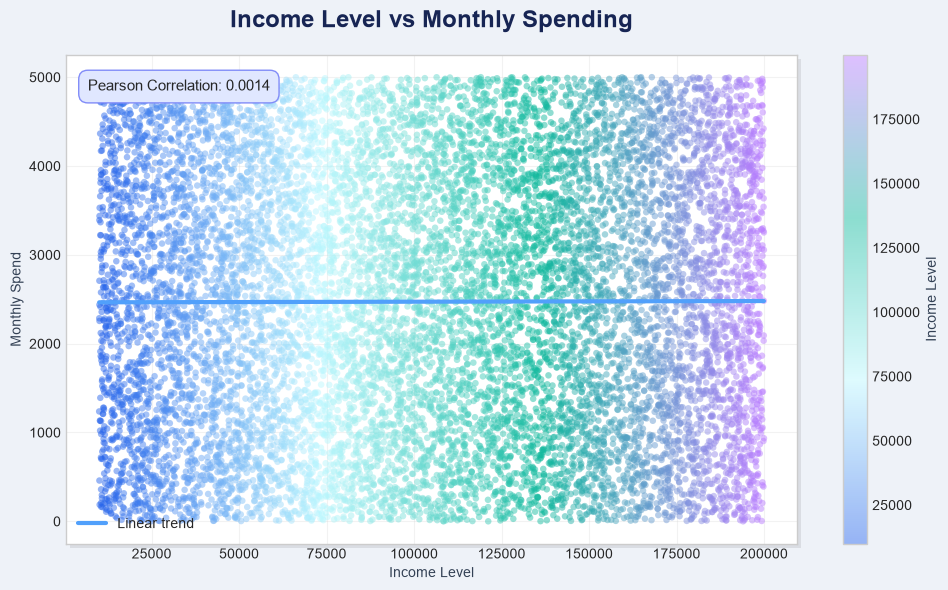

Pearson Correlation: 0.001446
Total Observations: 1000000


In [63]:
scatter_graph(
    "income_level",
    "monthly_spend",
    "Income Level vs Monthly Spending",
    cmap="viridis"
)

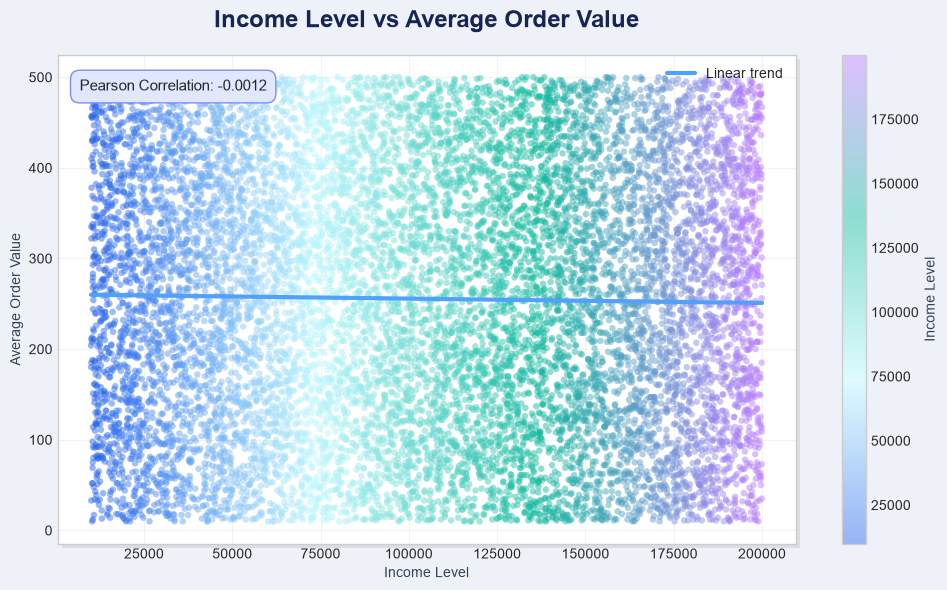

Pearson Correlation: -0.00125
Total Observations: 1000000


In [64]:
scatter_graph(
    "income_level",
    "average_order_value",
    "Income Level vs Average Order Value",
    cmap="plasma"
)

### Conclusion

- Income level has an almost negligible positive correlation with monthly spending.
- The Pearson correlation between income and monthly spending is approximately 0.0014.
- Income level also has a negligible negative correlation with average order value, approximately -0.0012.
- Higher-income customers do not necessarily demonstrate higher monthly spending or order values.
- Income alone is not a reliable indicator of customer financial contribution in this dataset.

**Business Insight:**

E-commerce platforms should identify high-value customers using actual purchasing patterns, shopping frequency, and customer engagement instead of relying only on income levels.

## 2.2 Engagement vs Conversion

This analysis investigates whether customers who spend more time browsing products or viewing product pages are more likely to complete purchases.

### Objectives:

- Examine the relationship between daily session time and purchase conversion rate.
- Investigate whether product views influence purchase conversion.
- Identify patterns between browsing activity and purchasing behaviour.
- Determine whether increased engagement leads to better conversion.

In [27]:
for col in [
    "daily_session_time_minutes",
    "product_views_per_day",
    "purchase_conversion_rate"
]:

    values = data[col]

    print(f"\n{col.upper()}")
    print("Mean:", round(np.mean(values), 2))
    print("Median:", round(np.median(values), 2))
    print("Minimum:", np.min(values))
    print("Maximum:", np.max(values))


DAILY_SESSION_TIME_MINUTES
Mean: 60.01
Median: 60.0
Minimum: 0.0
Maximum: 120.0

PRODUCT_VIEWS_PER_DAY
Mean: 25.02
Median: 25.0
Minimum: 0.0
Maximum: 50.0

PURCHASE_CONVERSION_RATE
Mean: 50.0
Median: 50.0
Minimum: 0.0
Maximum: 100.0


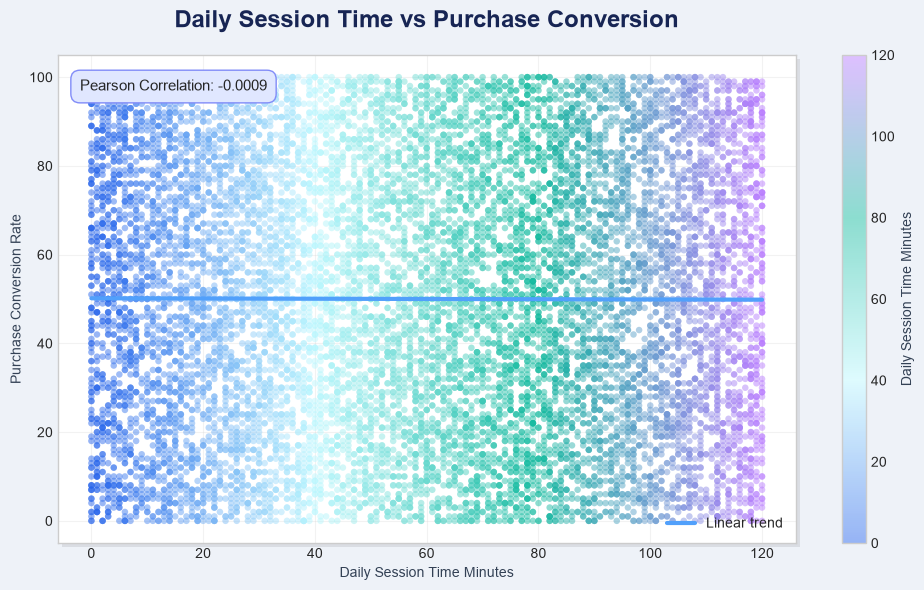

Pearson Correlation: -0.000892
Total Observations: 1000000


In [65]:
scatter_graph(
    "daily_session_time_minutes",
    "purchase_conversion_rate",
    "Daily Session Time vs Purchase Conversion",
    cmap="cividis"
)

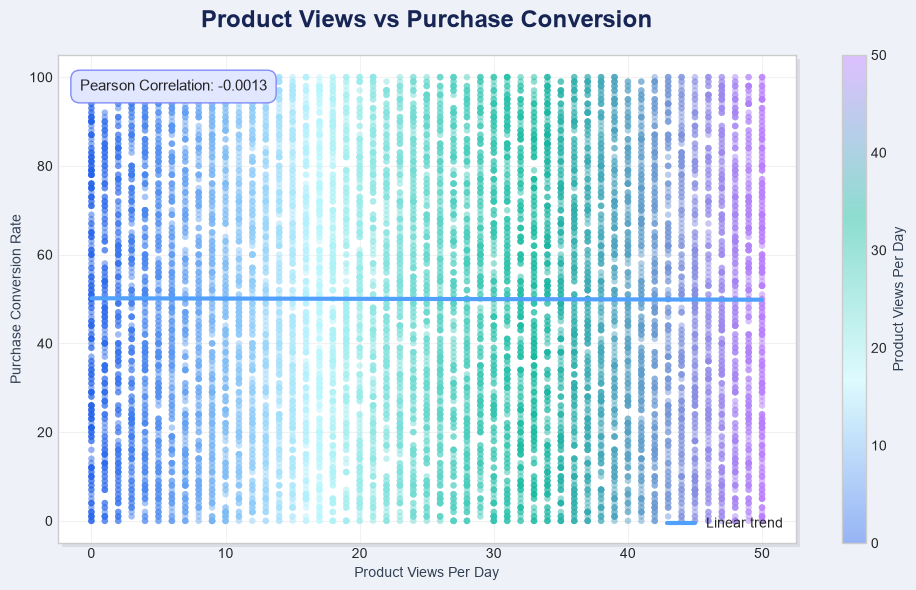

Pearson Correlation: -0.001331
Total Observations: 1000000


In [66]:
scatter_graph(
    "product_views_per_day",
    "purchase_conversion_rate",
    "Product Views vs Purchase Conversion",
    cmap="turbo"
)

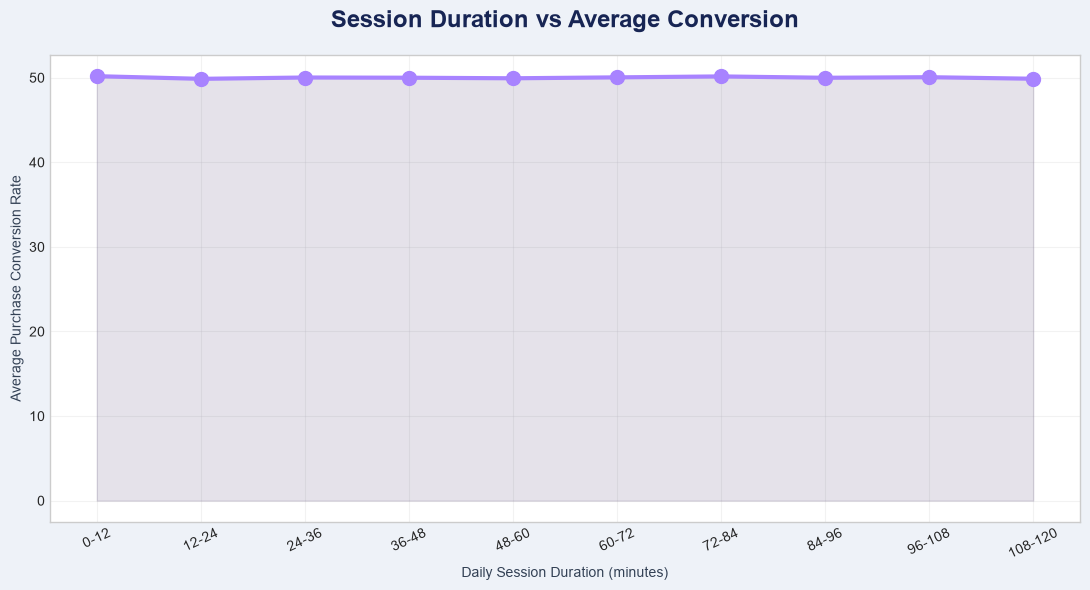

Average conversion by session duration:
0-12 minutes: 50.17
12-24 minutes: 49.86
24-36 minutes: 50.02
36-48 minutes: 49.99
48-60 minutes: 49.93
60-72 minutes: 50.03
72-84 minutes: 50.15
84-96 minutes: 49.99
96-108 minutes: 50.05
108-120 minutes: 49.87


In [84]:
x = data["daily_session_time_minutes"]
y = data["purchase_conversion_rate"]

# Divide session duration into 10 intervals

bins = np.linspace(x.min(), x.max(), 11)
groups = np.digitize(x, bins)

mean_conversion = []
interval_labels = []

for i in range(1, len(bins)):

    mask = groups == i

    if np.any(mask):

        mean_conversion.append(
            np.mean(y[mask])
        )

        interval_labels.append(
            f"{bins[i-1]:.0f}-{bins[i]:.0f}"
        )

# Create visual

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    interval_labels,
    mean_conversion,
    color="#A883FF",
    marker="o",
    markersize=10,
    linewidth=3
)

ax.fill_between(
    range(len(mean_conversion)),
    mean_conversion,
    color="#37265F",
    alpha=0.13
)

ax.set_title(
    "Session Duration vs Average Conversion",
    fontsize=17,
    pad=20
)

ax.set_xlabel("Daily Session Duration (minutes)")
ax.set_ylabel("Average Purchase Conversion Rate")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

print("Average conversion by session duration:")

for label, value in zip(
    interval_labels, mean_conversion
):
    print(f"{label} minutes: {value:.2f}")

### Conclusion

- Daily session time has an almost negligible negative correlation with purchase conversion (-0.0009).
- Product views per day also have a negligible negative correlation with conversion (-0.0013).
- Increased browsing activity does not necessarily lead to higher purchase conversion.
- The grouped graph helps visualize conversion changes across different session durations.
- No meaningful linear relationship between engagement and conversion is observed.

**Business Insight:**

E-commerce platforms should focus on meaningful customer engagement, relevant product recommendations, and simplified checkout experiences instead of simply increasing browsing time.

## 2.3 Loyalty Program Impact

This analysis examines whether loyalty program membership and coupon usage are associated with purchasing frequency, referrals, and product returns.

### Objectives:

- Compare purchasing frequency between loyalty members and non-members.
- Examine the relationship between coupon usage and referral count.
- Determine whether loyalty members generate more referrals.
- Investigate whether membership is associated with lower product return rates.
- Understand whether coupon usage is associated with repeat purchasing behaviour.

In [40]:
for group in [0, 1]:

    mask = (
        data["loyalty_program_member"] == group
    )

    label = "Member" if group == 1 else "Non-member"

    print(f"\n{label.upper()}")

    for col in [
        "weekly_purchases",
        "referral_count",
        "return_rate"
    ]:

        print(
            col,
            "Average:",
            round(np.mean(data[col][mask]), 3)
        )


NON-MEMBER
weekly_purchases Average: 10.002
referral_count Average: 5.007
return_rate Average: 50.013

MEMBER
weekly_purchases Average: 9.984
referral_count Average: 5.002
return_rate Average: 49.997



FULL DATASET GROUP STATISTICS
Non-member: Mean=10.002, Median=10.000, Count=500,182
Member: Mean=9.984, Median=10.000, Count=499,818


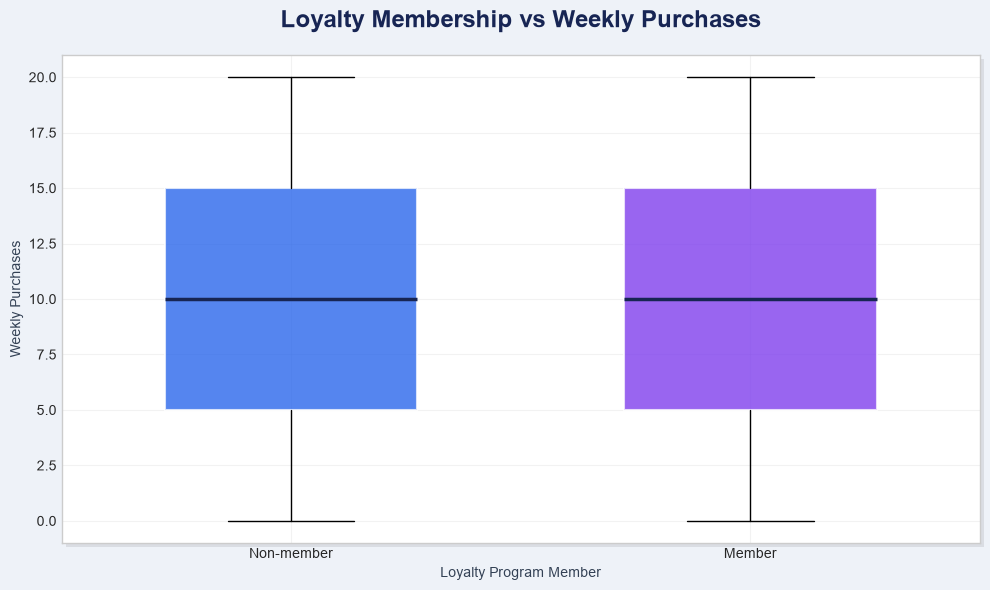

In [41]:
box_graph(
    "loyalty_program_member",
    "weekly_purchases",
    "Loyalty Membership vs Weekly Purchases"
)


FULL DATASET GROUP STATISTICS
Non-member: Mean=5.007, Median=5.000, Count=500,182
Member: Mean=5.002, Median=5.000, Count=499,818


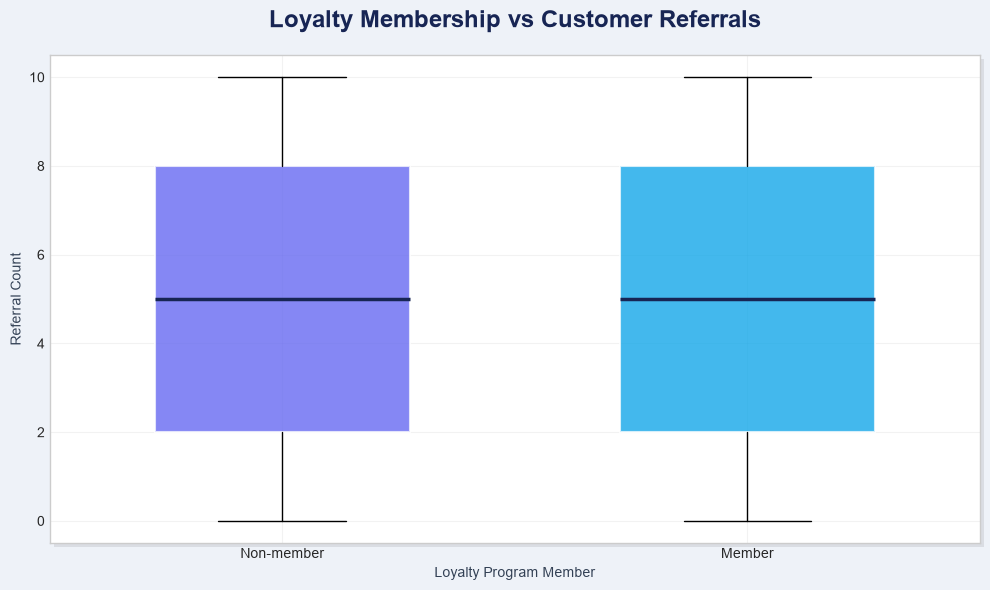

In [19]:
box_graph(
    "loyalty_program_member",
    "referral_count",
    "Loyalty Membership vs Customer Referrals"
)


FULL DATASET GROUP STATISTICS
Non-member: Mean=50.013, Median=50.000, Count=500,182
Member: Mean=49.997, Median=50.000, Count=499,818


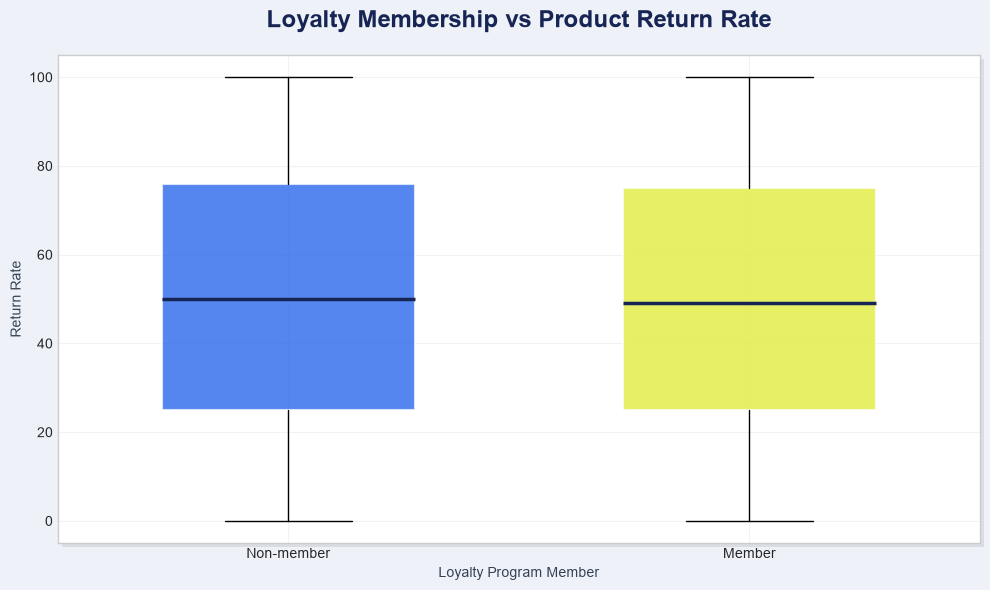

In [59]:
box_graph(
    "loyalty_program_member",
    "return_rate",
    "Loyalty Membership vs Product Return Rate"
)

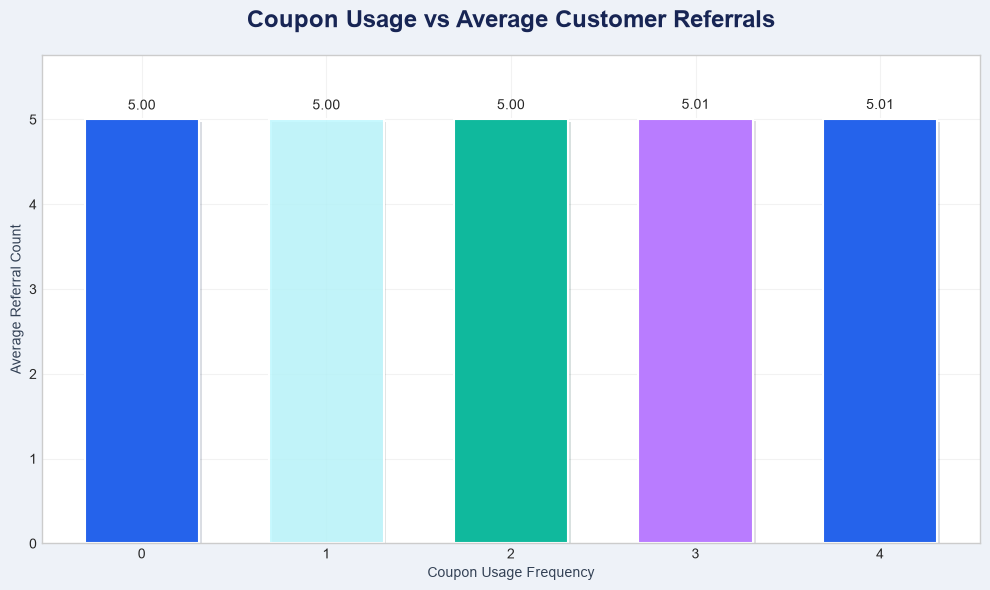


GROUP SUMMARY
0: Mean=5.00, Median=5.00, Count=199,891
1: Mean=5.00, Median=5.00, Count=199,898
2: Mean=5.00, Median=5.00, Count=199,239
3: Mean=5.01, Median=5.00, Count=199,987
4: Mean=5.01, Median=5.00, Count=200,985


In [68]:
mean_bar_graph(
    "coupon_usage_frequency",
    "referral_count",
    "Coupon Usage vs Average Customer Referrals"
)

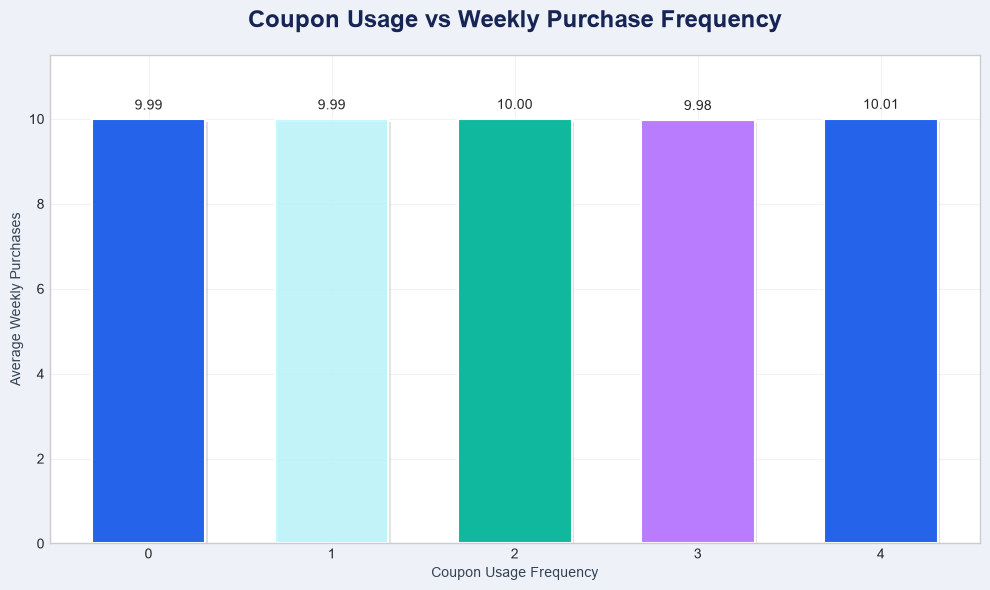


GROUP SUMMARY
0: Mean=9.99, Median=10.00, Count=199,891
1: Mean=9.99, Median=10.00, Count=199,898
2: Mean=10.00, Median=10.00, Count=199,239
3: Mean=9.98, Median=10.00, Count=199,987
4: Mean=10.01, Median=10.00, Count=200,985


In [69]:
mean_bar_graph(
    "coupon_usage_frequency",
    "weekly_purchases",
    "Coupon Usage vs Weekly Purchase Frequency"
)

### Conclusion

- Loyalty members have an average weekly purchase frequency of approximately 9.98, compared with 10.00 for non-members.
- Average referrals are approximately 5.00 for both groups.
- Average product return rates are approximately 50% for both groups.
- Coupon usage has almost no relationship with referrals or weekly purchasing frequency.
- Loyalty membership does not demonstrate a meaningful improvement in purchasing behaviour in this dataset.

**Business Insight:**

E-commerce platforms should evaluate loyalty programs using measurable customer retention, repeat purchase, and referral performance rather than assuming that membership automatically improves customer loyalty.

## 2.4 Psychographics & Spending

This analysis explores how customer psychological characteristics and brand preferences relate to actual shopping behaviour.

### Objectives:

- Examine the relationship between impulse buying score and actual impulse purchases.
- Investigate whether brand loyalty influences impulse purchases.
- Compare impulse buying tendencies among premium and non-premium subscribers.
- Understand the relationship between customer loyalty and purchasing tendencies.

In [70]:
for col in [
    "impulse_buying_score",
    "brand_loyalty_score",
    "impulse_purchases_per_month"
]:

    values = data[col]

    print(f"\n{col.upper()}")
    print("Mean:", round(np.mean(values), 2))
    print("Median:", round(np.median(values), 2))
    print("Minimum:", np.min(values))
    print("Maximum:", np.max(values))


IMPULSE_BUYING_SCORE
Mean: 5.0
Median: 5.0
Minimum: 0.0
Maximum: 10.0

BRAND_LOYALTY_SCORE
Mean: 5.0
Median: 5.0
Minimum: 0.0
Maximum: 10.0

IMPULSE_PURCHASES_PER_MONTH
Mean: 3.29
Median: 3.0
Minimum: 0.0
Maximum: 7.0


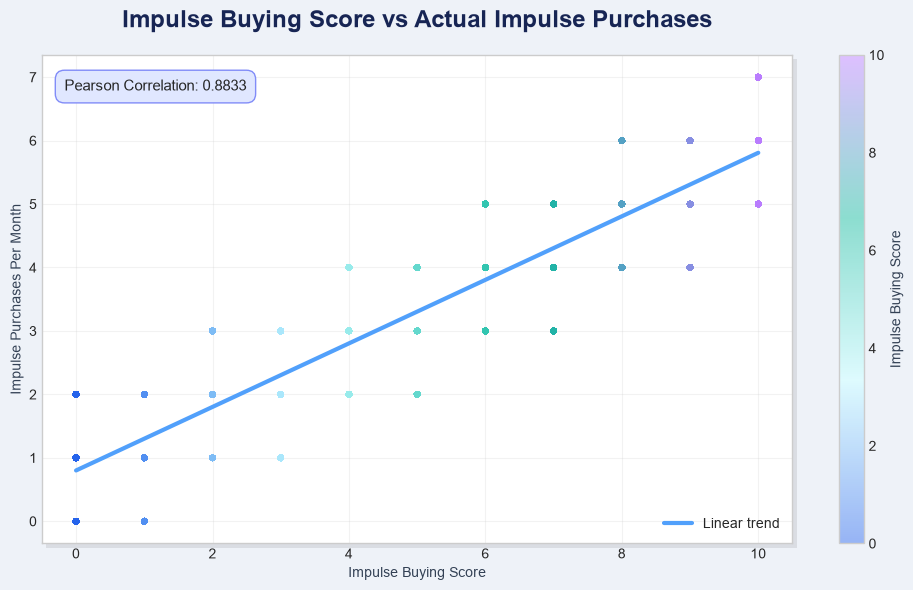

Pearson Correlation: 0.883329
Total Observations: 1000000


In [71]:
scatter_graph(
    "impulse_buying_score",
    "impulse_purchases_per_month",
    "Impulse Buying Score vs Actual Impulse Purchases",
    cmap="plasma"
)

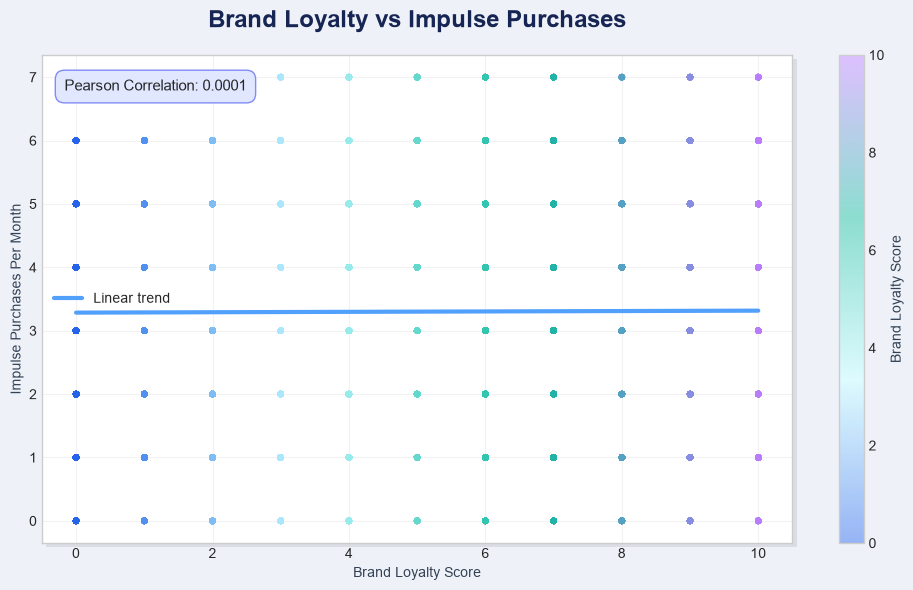

Pearson Correlation: 7.7e-05
Total Observations: 1000000


In [72]:
scatter_graph(
    "brand_loyalty_score",
    "impulse_purchases_per_month",
    "Brand Loyalty vs Impulse Purchases",
    cmap="viridis"
)

In [73]:
for group in [0, 1]:

    mask = (
        data["premium_subscription"] == group
    )

    label = "Premium" if group == 1 else "Non-premium"

    print(f"\n{label.upper()}")

    for col in [
        "brand_loyalty_score",
        "impulse_buying_score",
        "impulse_purchases_per_month"
    ]:

        print(
            col,
            "Average:",
            round(np.mean(data[col][mask]), 3)
        )


NON-PREMIUM
brand_loyalty_score Average: 4.999
impulse_buying_score Average: 5.0
impulse_purchases_per_month Average: 3.291

PREMIUM
brand_loyalty_score Average: 5.0
impulse_buying_score Average: 4.995
impulse_purchases_per_month Average: 3.289



FULL DATASET GROUP STATISTICS
Non-premium: Mean=5.000, Median=5.000, Count=640,585
Premium: Mean=4.995, Median=5.000, Count=359,415


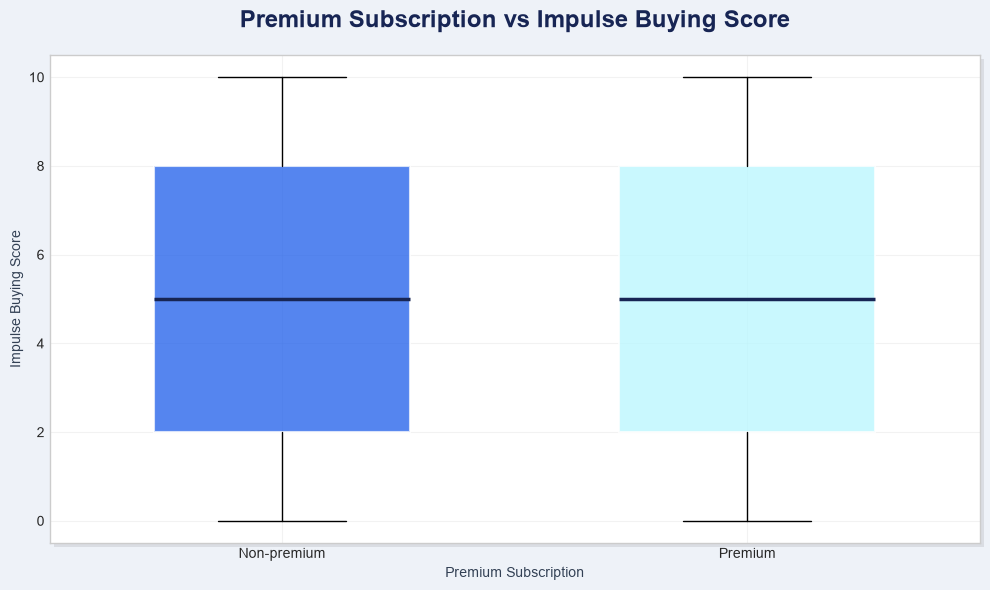

In [74]:
box_graph(
    "premium_subscription",
    "impulse_buying_score",
    "Premium Subscription vs Impulse Buying Score"
)


FULL DATASET GROUP STATISTICS
Non-premium: Mean=4.999, Median=5.000, Count=640,585
Premium: Mean=5.000, Median=5.000, Count=359,415


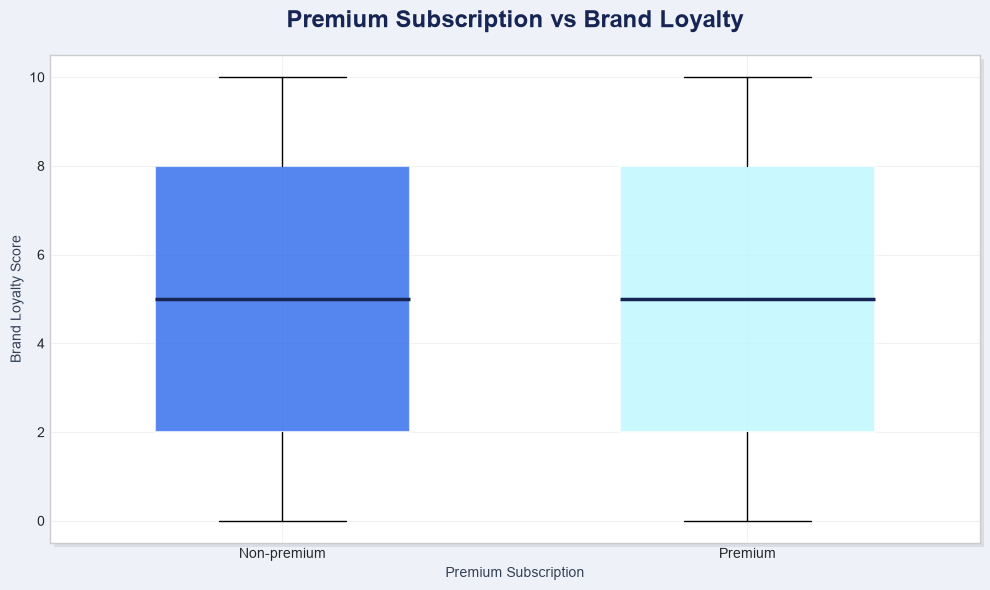

In [75]:
box_graph(
    "premium_subscription",
    "brand_loyalty_score",
    "Premium Subscription vs Brand Loyalty"
)

### Conclusion

- Impulse buying score has a strong positive correlation of approximately 0.8833 with impulse purchases per month.
- Customers with higher impulse-buying tendencies generally make more spontaneous purchases.
- Brand loyalty score has an almost negligible correlation with impulse purchases.
- Premium and non-premium subscribers have very similar average brand loyalty and impulse-buying scores.
- Premium subscription status does not demonstrate a meaningful relationship with these psychological characteristics.

**Business Insight:**

E-commerce platforms can use customer purchasing tendencies to improve personalized product recommendations, product suggestions, and promotional strategies.

## 2.5 Stress & Financial Decisions

This analysis investigates whether financial stress and budgeting preferences are associated with monthly customer spending patterns.

### Objectives:

- Examine the relationship between financial stress and monthly spending.
- Compare financial stress levels across different budgeting styles.
- Investigate spending differences between strict, moderate, and loose budgeters.
- Determine whether higher financial stress is associated with lower spending.

In [76]:
for col in [
    "stress_from_financial_decisions",
    "monthly_spend"
]:

    values = data[col]

    print(f"\n{col.upper()}")
    print("Mean:", round(np.mean(values), 2))
    print("Median:", round(np.median(values), 2))
    print("Minimum:", np.min(values))
    print("Maximum:", np.max(values))


STRESS_FROM_FINANCIAL_DECISIONS
Mean: 5.0
Median: 5.0
Minimum: 0.0
Maximum: 10.0

MONTHLY_SPEND
Mean: 2498.78
Median: 2498.0
Minimum: 0.0
Maximum: 5000.0


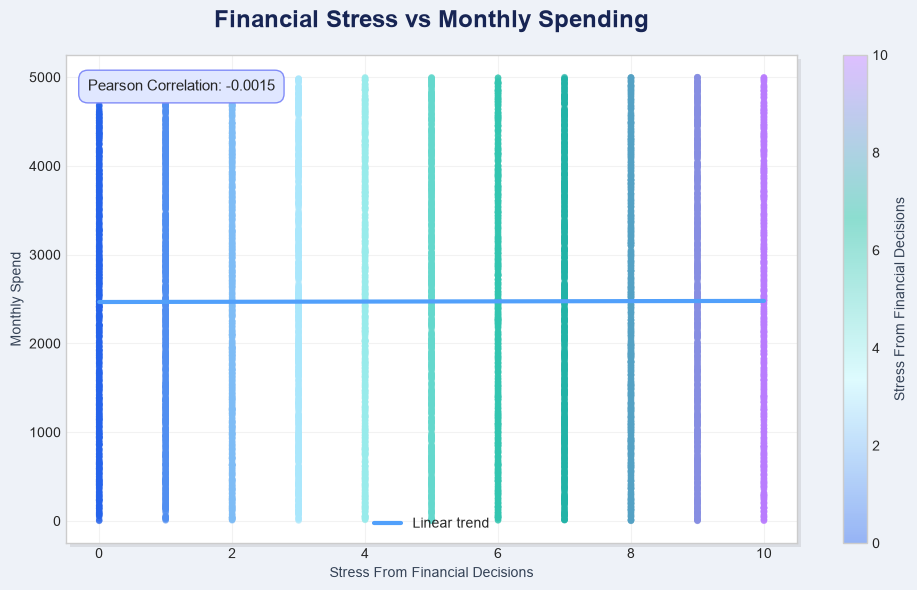

Pearson Correlation: -0.001465
Total Observations: 1000000


In [77]:
scatter_graph(
    "stress_from_financial_decisions",
    "monthly_spend",
    "Financial Stress vs Monthly Spending",
    cmap="magma"
)


FULL DATASET GROUP STATISTICS
Strict: Mean=4.997, Median=5.000, Count=332,791
Loose: Mean=5.001, Median=5.000, Count=333,438
Moderate: Mean=4.998, Median=5.000, Count=333,771


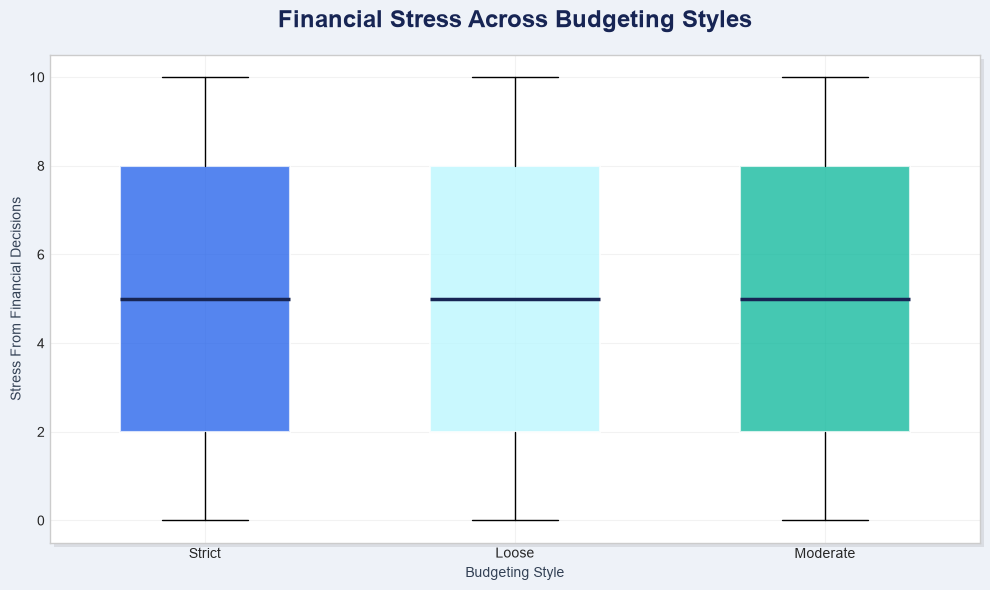

In [78]:
box_graph(
    "budgeting_style",
    "stress_from_financial_decisions",
    "Financial Stress Across Budgeting Styles"
)

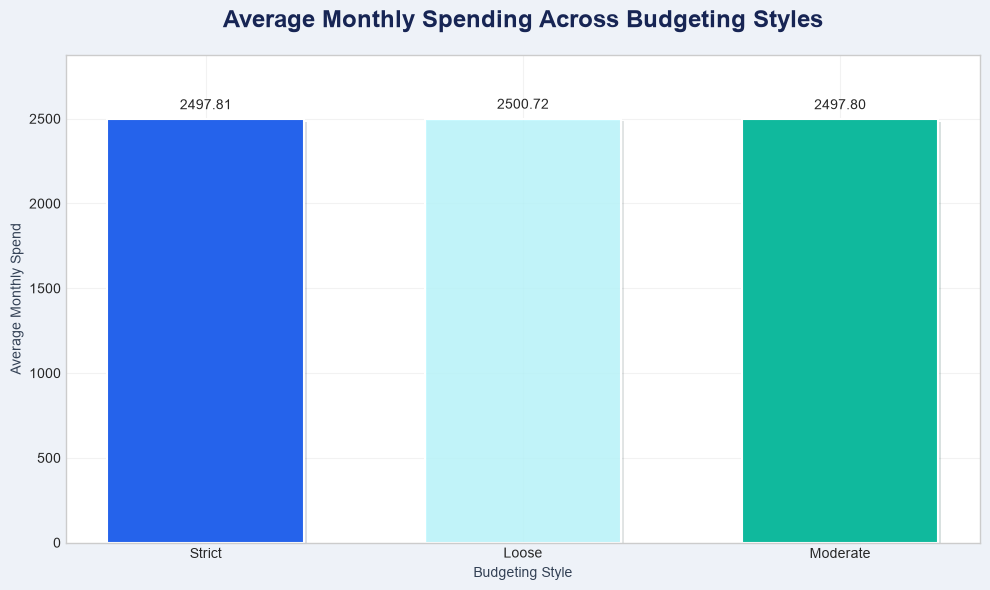


GROUP SUMMARY
Strict: Mean=2497.81, Median=2497.00, Count=332,791
Loose: Mean=2500.72, Median=2497.00, Count=333,438
Moderate: Mean=2497.80, Median=2499.00, Count=333,771


In [79]:
mean_bar_graph(
    "budgeting_style",
    "monthly_spend",
    "Average Monthly Spending Across Budgeting Styles"
)

### Conclusion

- Financial stress has an almost negligible negative correlation with monthly spending (-0.0015).
- Loose, Moderate, and Strict budgeters have very similar average financial stress levels.
- Average monthly spending also remains relatively similar across budgeting categories.
- Higher financial stress does not demonstrate a meaningful reduction in monthly spending in this dataset.
- Budgeting preferences alone do not provide strong evidence of different spending behaviours.

**Business Insight:**

E-commerce platforms should not assume that financially stressed customers necessarily spend less. Transparent pricing, spending summaries, and personalized shopping experiences can help customers manage their purchases.

## 2.6 Overall Bivariate Analysis Summary

The bivariate analysis examined relationships between customer income, spending, platform engagement, loyalty, psychological characteristics, and financial stress.

The following section summarizes the major statistical relationships discovered in the dataset.

In [80]:
# Selected business-related variable pairs

pairs = [
    ("income_level", "monthly_spend"),
    ("income_level", "average_order_value"),

    ("daily_session_time_minutes", "purchase_conversion_rate"),
    ("product_views_per_day", "purchase_conversion_rate"),

    ("coupon_usage_frequency", "referral_count"),
    ("coupon_usage_frequency", "weekly_purchases"),

    ("impulse_buying_score", "impulse_purchases_per_month"),
    ("brand_loyalty_score", "impulse_purchases_per_month"),

    ("stress_from_financial_decisions", "monthly_spend")
]

print("=" * 90)
print("BIVARIATE CORRELATION SUMMARY")
print("=" * 90)

for x_col, y_col in pairs:

    correlation = np.corrcoef(
        data[x_col],
        data[y_col]
    )[0, 1]

    if abs(correlation) < 0.10:
        strength = "Negligible"

    elif abs(correlation) < 0.30:
        strength = "Weak"

    elif abs(correlation) < 0.70:
        strength = "Moderate"

    else:
        strength = "Strong"

    print(
        f"\n{x_col} vs {y_col}\n"
        f"Pearson Correlation: {correlation:.4f}\n"
        f"Relationship Strength: {strength}"
    )

BIVARIATE CORRELATION SUMMARY

income_level vs monthly_spend
Pearson Correlation: 0.0014
Relationship Strength: Negligible

income_level vs average_order_value
Pearson Correlation: -0.0012
Relationship Strength: Negligible

daily_session_time_minutes vs purchase_conversion_rate
Pearson Correlation: -0.0009
Relationship Strength: Negligible

product_views_per_day vs purchase_conversion_rate
Pearson Correlation: -0.0013
Relationship Strength: Negligible

coupon_usage_frequency vs referral_count
Pearson Correlation: 0.0009
Relationship Strength: Negligible

coupon_usage_frequency vs weekly_purchases
Pearson Correlation: 0.0004
Relationship Strength: Negligible

impulse_buying_score vs impulse_purchases_per_month
Pearson Correlation: 0.8833
Relationship Strength: Strong

brand_loyalty_score vs impulse_purchases_per_month
Pearson Correlation: 0.0001
Relationship Strength: Negligible

stress_from_financial_decisions vs monthly_spend
Pearson Correlation: -0.0015
Relationship Strength: Negligi

### Overall Conclusion

The bivariate analysis identified several important relationships between customer characteristics and shopping behaviour.

#### Key Findings:

- Income level has almost no linear relationship with monthly spending or average order value.
- Platform engagement metrics do not demonstrate meaningful linear relationships with purchase conversion.
- Loyalty program membership does not show meaningful differences in average purchase frequency, referrals, or return rates.
- Coupon usage has almost no relationship with referral count or weekly purchases.
- Impulse buying tendency has a strong positive relationship with actual impulse purchases.
- Brand loyalty does not demonstrate a meaningful relationship with impulse purchasing.
- Financial stress has almost no relationship with monthly spending.

#### Business Recommendations:

1. Improve customer segmentation using actual purchasing behaviour.
2. Focus on meaningful engagement and improved product discovery.
3. Evaluate loyalty programs using measurable customer retention.
4. Personalize product recommendations using customer shopping tendencies.
5. Provide transparent pricing and tools that support responsible spending.

#### Final Observation:

Among the relationships examined, impulse buying tendency and actual impulse purchases show the strongest association.

Most other relationships are negligible in the supplied synthetic dataset.

These findings suggest that customer shopping behaviour cannot be explained by a single demographic or financial variable.